<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
!pip install -q keras-tuner

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, SGD

import keras_tuner as kt

In [26]:
from google.colab import drive
import numpy as np
import pandas as pd
import tensorflow as tf

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Set seeds & load directly from your 'deeplearning' folder
np.random.seed(42)
tf.random.set_seed(42)

path = "/content/drive/MyDrive/deeplearning/housing.csv (1) (1).zip"
df = pd.read_csv(path)

print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0

In [27]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(
    df["total_bedrooms"].median()
)

In [29]:
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Separate features (X) and target (y)
# Let's drop 'ocean_proximity' for simplicity or encode it later, and drop target 'median_house_value'
X = df.drop(columns=['median_house_value', 'ocean_proximity'])
y = df['median_house_value']

# 2. Perform train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Check for NaN or Inf values in y_train
print("NaN in y_train:", np.isnan(y_train).sum())
print("Inf in y_train:", np.isinf(y_train).sum())
print("Min:", y_train.min())
print("Max:", y_train.max())

NaN in y_train: 0
Inf in y_train: 0
Min: 14999.0
Max: 500001.0


In [31]:
import numpy as np

print("NaN in X_train:", np.isnan(X_train).sum().sum())
print("Inf in X_train:", np.isinf(X_train).sum().sum())

print("X_train dtypes:\n", X_train.dtypes)
print("\ny_train dtype:", y_train.dtype)

NaN in X_train: 0
Inf in X_train: 0
X_train dtypes:
 longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
dtype: object

y_train dtype: float64


In [33]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(
    X,    y,
    test_size=0.20,
    random_state=42
)

X_train = pd.get_dummies(
    X_train,
    columns=["ocean_proximity"],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=["ocean_proximity"],
    drop_first=True
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN'],
      dtype='object')


In [43]:
from sklearn.preprocessing import StandardScaler

# Scale the features (X) as neural networks perform much better with scaled inputs
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale the target (y)
y_scaler = StandardScaler()
# Since y_train/y_test are numpy arrays or Series, we reshape them directly safely
y_train_scaled = y_scaler.fit_transform(np.array(y_train).reshape(-1, 1))
y_test_scaled = y_scaler.transform(np.array(y_test).reshape(-1, 1))

def build_model(hp):
    model = Sequential()
    model.add(Input(shape=(X_train_scaled.shape[1],)))

    # First Hidden Layer
    model.add(
        Dense(
            units=hp.Int(
                "units",
                min_value=32,
                max_value=128,
                step=32
            ),
            activation="relu"
        )
    )
    model.add(
        Dropout(
            hp.Float(
                "dropout",
                0.0,
                0.4,
                step=0.2
            )
        )
    )

    # Additional Hidden Layers
    for i in range(
        hp.Int("hidden_layers", 1, 2)
    ):
        model.add(
            Dense(
                units=hp.Int(
                    f"units_{i}",
                    min_value=32,
                    max_value=128,
                    step=32
                ),
                activation="relu"
            )
        )

    # Output Layer
    model.add(Dense(1))

    # Optimizer
    optimizer = hp.Choice(
        "optimizer",
        ["adam", "sgd"]
    )

    learning_rate = hp.Choice(
        "learning_rate",
        [0.01, 0.001, 0.0001]
    )

    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    else:
        opt = SGD(learning_rate=learning_rate)

    model.compile(
        optimizer=opt,
        loss="mse",
        metrics=["mae"]
    )

    return model

In [44]:
# Cell merged with cell QgVHam6zKImG to avoid scoping NameError

In [45]:
tuner = kt.RandomSearch(
    build_model,
objective="val_loss",
max_trials=5,
overwrite=True,
directory="Regression_Tuning",
project_name="CaliforniaHousing"
)

In [17]:
print("\nTesting AND Gate")
test = np.array([
[0,0],
[0,1],
[1,0],
[1,1]
])
print(and_model.predict(test))
print("\nTesting OR Gate")
print(or_model.predict(test))
print("\nTesting NOT Gate")
print(not_model.predict(np.array([[0],[1]])))


Testing AND Gate
[0 0 0 1]

Testing OR Gate
[0 1 1 1]

Testing NOT Gate
[1 0]


In [46]:
tuner.search(
X_train,
y_train,
validation_split=0.20,
epochs=10,
batch_size=32,
verbose=1
)

Trial 5 Complete [00h 00m 21s]
val_loss: nan

Best val_loss So Far: 1.6362364292144775
Total elapsed time: 00h 02m 09s


In [47]:
best_model = tuner.get_best_models(1)[0]
print("\nBest Hyperparameters\n")
best_hp = tuner.get_best_hyperparameters(1)[0]
print(best_hp.values)


Best Hyperparameters

{'units': 96, 'dropout': 0.2, 'hidden_layers': 1, 'units_0': 64, 'optimizer': 'adam', 'learning_rate': 0.001, 'units_1': 96}


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [48]:
history = best_model.fit(
  X_train,
  y_train,
  validation_split=0.20,
  epochs=15,
  batch_size=32,
  verbose=1
)

Epoch 1/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - loss: 72.4901 - mae: 3.9187 - val_loss: 24.4445 - val_mae: 2.3006
Epoch 2/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 23.5249 - mae: 2.7927 - val_loss: 9.4309 - val_mae: 1.6240
Epoch 3/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 5.5417 - mae: 1.4221 - val_loss: 2.3234 - val_mae: 0.8180
Epoch 4/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 4.8245 - mae: 1.2846 - val_loss: 6.7792 - val_mae: 1.1455
Epoch 5/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.7867 - mae: 1.1465 - val_loss: 1.2949 - val_mae: 0.8034
Epoch 6/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 3.3468 - mae: 1.1290 - val_loss: 1.0939 - val_mae: 0.7315
Epoch 7/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 1.9790 - mae: 0.9303 - val_loss: 0.9304 - val_mae: 0.7221
Epoch 8/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.2087 - mae: 0.9741 - val_loss: 12.2046 - val_mae: 1.6804
Epoch 9/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

In [49]:
loss, mae = best_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest MSE :", loss)
print("Test MAE :", mae)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9536 - mae: 0.6709

Test MSE : 0.9535521268844604
Test MAE : 0.6708582639694214


In [50]:
predictions = best_model.predict(X_test)

predictions_original = y_scaler.inverse_transform(predictions)
actual_original = y_scaler.inverse_transform(y_test)

comparison = pd.DataFrame({
    "Actual": actual_original.flatten()[:10],
    "Predicted": predictions_original.flatten()[:10]
})

print(comparison)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


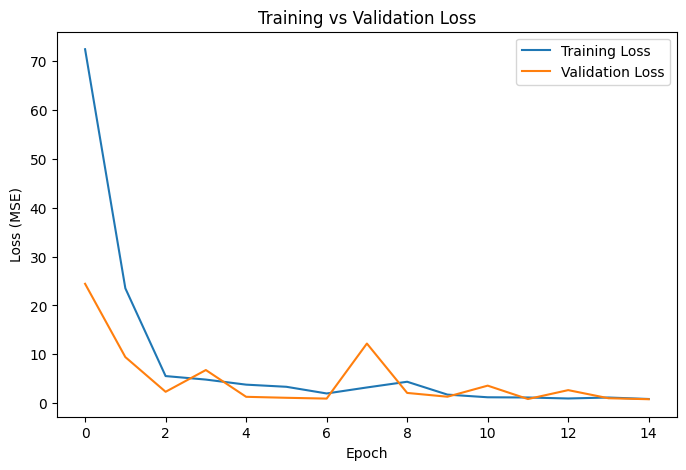

In [51]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

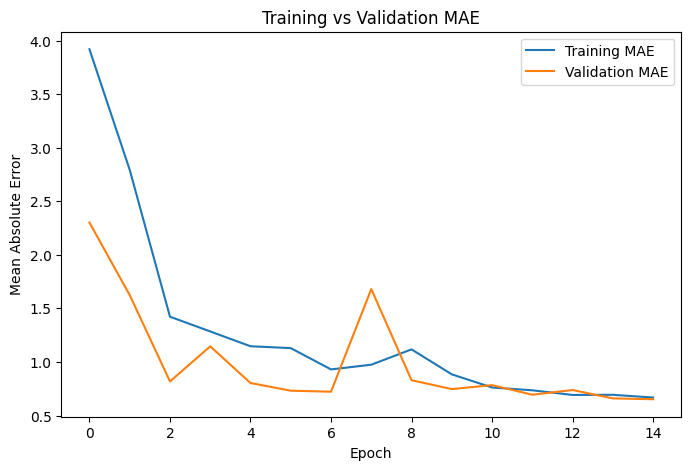

In [52]:
plt.figure(figsize=(8,5))
plt.plot(
history.history["mae"],
label="Training MAE"
)
plt.plot(
history.history["val_mae"],
label="Validation MAE"
)
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.title("Training vs Validation MAE")
plt.legend()
plt.show()